## a. Problem statement
Predict whether a breast tumour is **malignant (0)** or **benign (1)** from numeric measurements of cell nuclei computed from a digitised fine-needle-aspirate image. This is a binary classification problem. Five classifiers are trained on the same data and compared on Accuracy, AUC, Precision, Recall, F1 and MCC.

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix, roc_curve)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_style("whitegrid")

## b. Dataset description (Step 1)
**Breast Cancer Wisconsin (Diagnostic)** - UCI Machine Learning Repository (dataset id 17), loaded with the `ucimlrepo` package.
Requirements: at least 12 features and 500 instances.

following is the code i copied from UCI website to load the dataset


In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17)

# data (as pandas dataframes)
X = breast_cancer_wisconsin_diagnostic.data.features
y = breast_cancer_wisconsin_diagnostic.data.targets

# metadata
print(breast_cancer_wisconsin_diagnostic.metadata)

# variable information
print(breast_cancer_wisconsin_diagnostic.variables)

{'uci_id': 17, 'name': 'Breast Cancer Wisconsin (Diagnostic)', 'repository_url': 'https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic', 'data_url': 'https://archive.ics.uci.edu/static/public/17/data.csv', 'abstract': 'Diagnostic Wisconsin Breast Cancer Database.', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 569, 'num_features': 30, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['Diagnosis'], 'index_col': ['ID'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1993, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C5DW2B', 'creators': ['William Wolberg', 'Olvi Mangasarian', 'Nick Street', 'W. Street'], 'intro_paper': {'ID': 230, 'type': 'NATIVE', 'title': 'Nuclear feature extraction for breast tumor diagnosis', 'authors': 'W. Street, W. Wolberg, O. Mangasarian', 'venue': 'Electronic imaging', 'year': 1993, 'journal': None, 'DOI': '1

In [3]:
y = y["Diagnosis"].map({"M": 0, "B": 1}).rename("target")
df = pd.concat([X, y], axis=1)   # 30 features + 'target'
print("Instances:", df.shape[0])
print("Features :", df.shape[1] - 1)
print("Missing values:", int(df.isna().sum().sum()))
print("Target meaning: 0 = malignant, 1 = benign")
print(df["target"].value_counts().rename({0: "malignant (0)", 1: "benign (1)"}))
df.head()

Instances: 569
Features : 30
Missing values: 0
Target meaning: 0 = malignant, 1 = benign
target
benign (1)       357
malignant (0)    212
Name: count, dtype: int64


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [4]:
df.describe().T.round(3).head(12)

,count,mean,std,min,25%,50%,75%,max
radius1,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
texture1,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
perimeter1,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
area1,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
smoothness1,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
compactness1,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
concavity1,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
concave_points1,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
symmetry1,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
fractal_dimension1,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


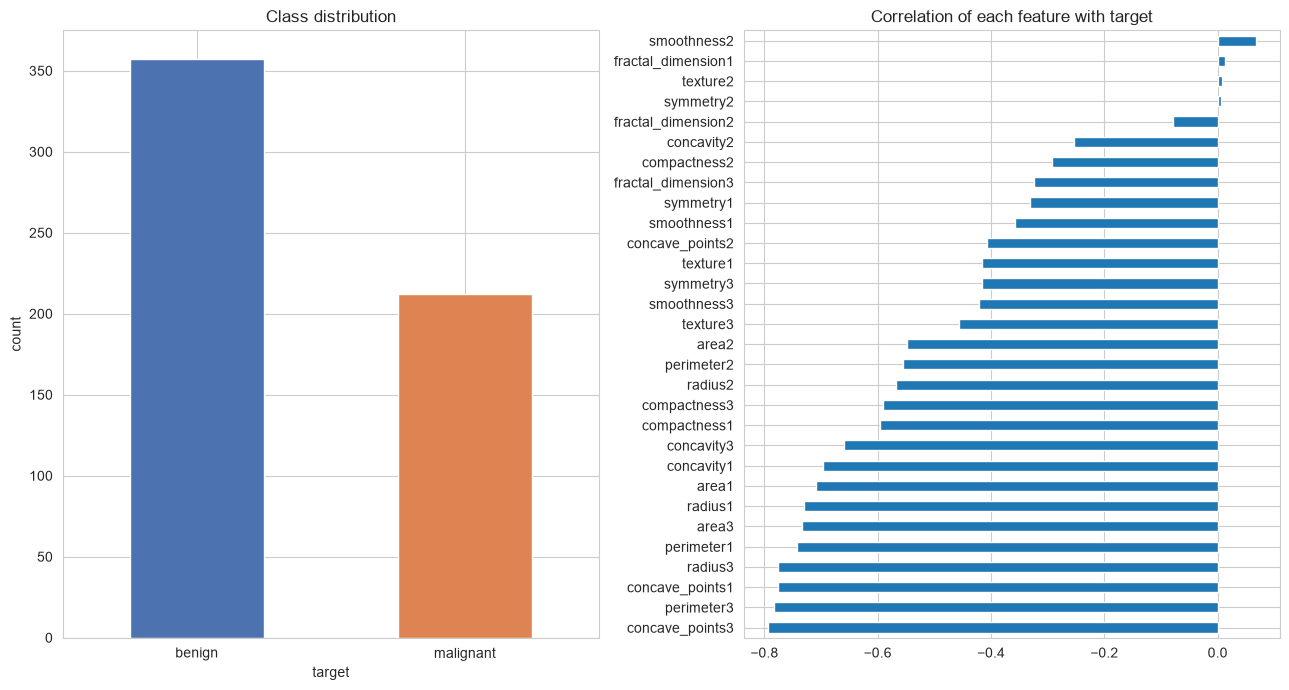

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df["target"].map({0: "malignant", 1: "benign"}).value_counts().plot(kind="bar", ax=axes[0], color=["#4c72b0", "#dd8452"])
axes[0].set_title("Class distribution"); axes[0].set_ylabel("count"); axes[0].tick_params(axis="x", rotation=0)
df.corr()["target"].drop("target").sort_values().plot(kind="barh", ax=axes[1], figsize=(13, 7))
axes[1].set_title("Correlation of each feature with target")
plt.tight_layout(); plt.show()

## Train / test split
80 % train, 20 % test, stratified so both sets keep the class ratio. The test split is later saved as `test_data.csv` (features + target) for the Streamlit app.

In [6]:
X = df.drop(columns="target")
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Test class counts:", y_test.value_counts().to_dict())

Train: (455, 30)  Test: (114, 30)
Test class counts: {1: 72, 0: 42}


## Step 2: Models and evaluation metrics
Logistic Regression, KNN and SVM are scale-sensitive, so a `StandardScaler` is placed inside a `Pipeline` with each of them. This keeps each saved model self-contained. Decision Tree and Gaussian Naive Bayes do not need scaling.

In [7]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"trained: {name}")

trained: Logistic Regression
trained: Decision Tree
trained: KNN
trained: Naive Bayes
trained: Support Vector Machine


In [8]:
def evaluate(model, X, y):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)[:, 1]
    return {
        "Accuracy":  accuracy_score(y, y_pred),
        "AUC":       roc_auc_score(y, y_prob),
        "Precision": precision_score(y, y_pred),
        "Recall":    recall_score(y, y_pred),
        "F1":        f1_score(y, y_pred),
        "MCC":       matthews_corrcoef(y, y_pred),
    }

results = pd.DataFrame(
    [{"ML Model Name": n, **evaluate(m, X_test, y_test)} for n, m in models.items()]
).set_index("ML Model Name").round(4)
results

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623
Decision Tree,0.9211,0.9163,0.9565,0.9167,0.9362,0.8341
KNN,0.9737,0.9884,0.9600,1.0000,0.9796,0.9442
Naive Bayes,0.9386,0.9878,0.9452,0.9583,0.9517,0.8676
Support Vector Machine,0.9825,0.9950,0.9861,0.9861,0.9861,0.9623


### Comparison table 

In [9]:
print(results.reset_index().to_markdown(index=False) if hasattr(pd.DataFrame, "to_markdown") and
      __import__("importlib").util.find_spec("tabulate") else results.reset_index().to_string(index=False))

| ML Model Name          |   Accuracy |    AUC |   Precision |   Recall |     F1 |    MCC |
|:-----------------------|-----------:|-------:|------------:|---------:|-------:|-------:|
| Logistic Regression    |     0.9825 | 0.9954 |      0.9861 |   0.9861 | 0.9861 | 0.9623 |
| Decision Tree          |     0.9211 | 0.9163 |      0.9565 |   0.9167 | 0.9362 | 0.8341 |
| KNN                    |     0.9737 | 0.9884 |      0.96   |   1      | 0.9796 | 0.9442 |
| Naive Bayes            |     0.9386 | 0.9878 |      0.9452 |   0.9583 | 0.9517 | 0.8676 |
| Support Vector Machine |     0.9825 | 0.995  |      0.9861 |   0.9861 | 0.9861 | 0.9623 |


In [10]:
# Highlight the best value in each column
results.style.highlight_max(axis=0, color="#c6efce").format("{:.4f}")

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623
Decision Tree,0.9211,0.9163,0.9565,0.9167,0.9362,0.8341
KNN,0.9737,0.9884,0.9600,1.0000,0.9796,0.9442
Naive Bayes,0.9386,0.9878,0.9452,0.9583,0.9517,0.8676
Support Vector Machine,0.9825,0.9950,0.9861,0.9861,0.9861,0.9623


### Confusion matrices

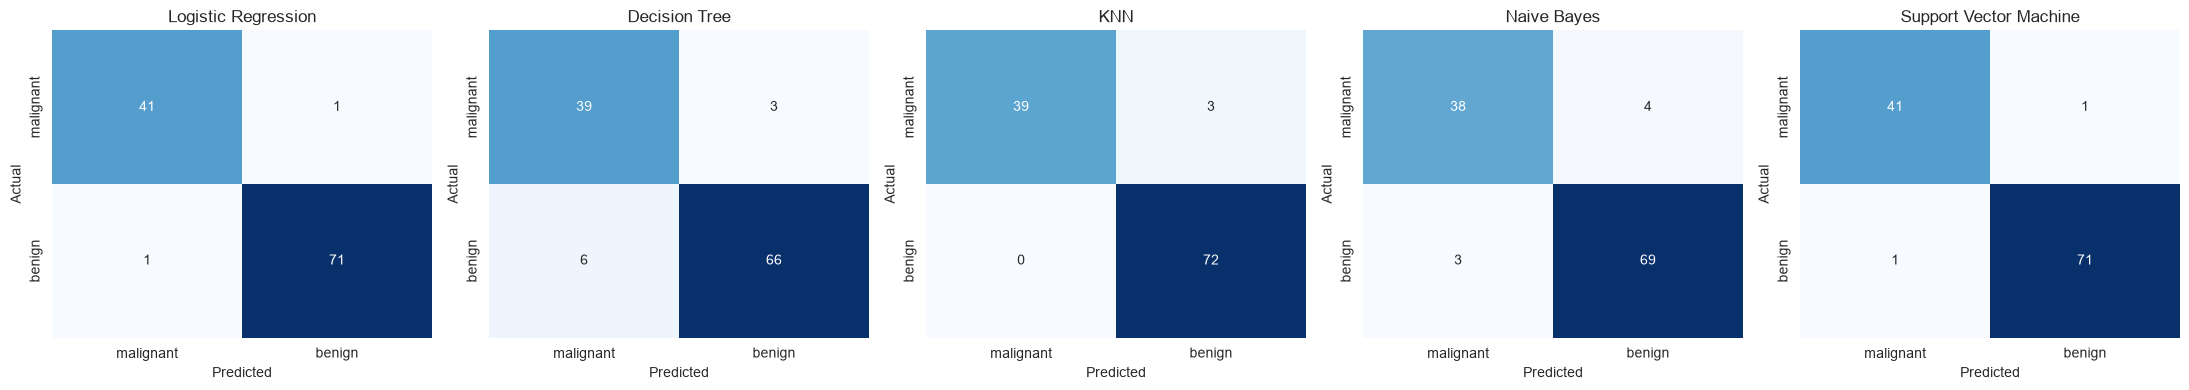

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["malignant", "benign"], yticklabels=["malignant", "benign"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

### ROC curves

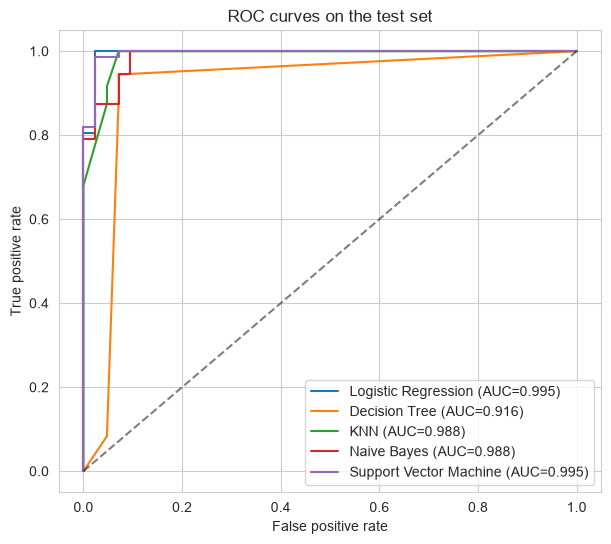

In [12]:
plt.figure(figsize=(7, 6))
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC={results.loc[name, 'AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves on the test set"); plt.legend(loc="lower right"); plt.show()

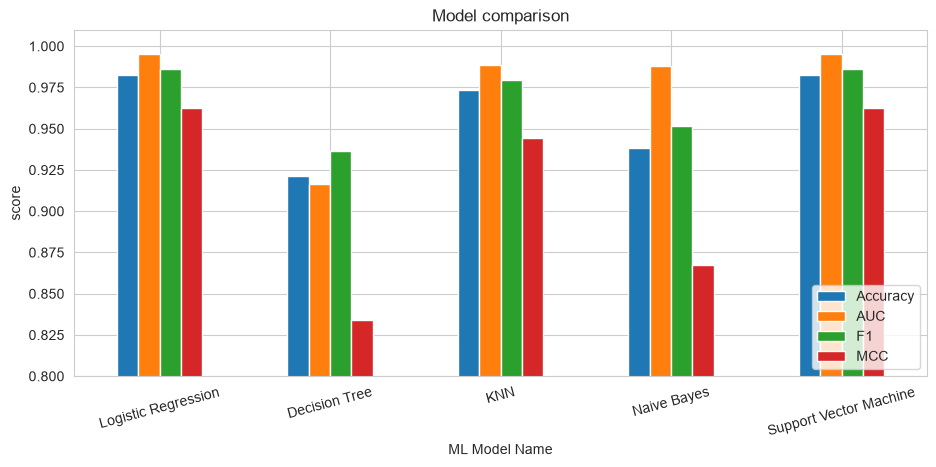

In [13]:
results[["Accuracy", "AUC", "F1", "MCC"]].plot(kind="bar", figsize=(11, 4.5), ylim=(0.8, 1.01), rot=15)
plt.title("Model comparison"); plt.ylabel("score"); plt.legend(loc="lower right"); plt.show()

## Observations on model performance
*(Based on the run with `random_state=42` )

| ML Model Name | Observation about model performance |
|---|---|
| Logistic Regression | Joint-best accuracy, F1 and MCC with only 2 of 114 test errors and the highest AUC. Standardised features make the classes close to linearly separable, so a simple linear model is enough. |
| Decision Tree | Weakest model: lowest accuracy, AUC and MCC (9 errors). Hard splits and coarse probability outputs lower AUC; interpretable but generalises worst here. |
| KNN | Perfect recall (no benign case missed) but 3 malignant tumours predicted as benign, so precision is lower. Depends on feature scaling and the choice of k. |
| Naive Bayes | Strong AUC but lower accuracy and MCC. The independence assumption is violated because radius, perimeter and area are highly correlated. |
| Support Vector Machine | Matches Logistic Regression on all threshold metrics with practically the same AUC; the RBF kernel works well on scaled features at higher computational cost. |
| **Overall winner** | **Logistic Regression** - tied with SVM on accuracy / F1 / MCC and marginally ahead on AUC, while simpler and more interpretable. With a 114-row test set the top two differ by about one prediction. |